# Interface charge reconstruction: a computational model test

**This notebook runs a dimensionless minimal tight-binding model, not a nickelate experiment.** It has no measured material parameters and calculates charge redistribution only. It does not calculate superconductivity, resistance, magnetism, or Tc.

**Hypothesis tested:** An interface perturbation creates a layer-resolved charge change that decays exponentially away from the interface. The notebook compares an interface onsite potential with a hopping barrier, a two-layer electrostatic proxy, and a uniform hopping-change proxy. It tests thicknesses and fillings and reports a k-grid convergence check.

**Run in Google Colab:** Upload this `.ipynb` file through Colab's *File → Upload notebook*, then choose *Runtime → Run all*. The same code has been executed locally with Python, NumPy, and Matplotlib; it was not run in a Google Colab account.

All energies, hoppings, fillings, and potentials are illustrative dimensionless inputs—not measured nickelate values. The assumed fixed total filling forces charge compensation within the modeled film. Interpret the results only within these assumptions.


In [1]:
#!/usr/bin/env python3
"""Minimal layered tight-binding sensitivity experiment for nickelate interfaces.

This is a deliberately non-material-specific, non-interacting model. Energies are
in units of in-plane hopping t; no measured nickelate parameters are fitted.
It calculates layer charge redistribution only. It does NOT calculate pairing,
Tc, resistance, magnetism, oxygen chemistry, or prove superconductivity.
"""
from pathlib import Path
import csv
import math
import sys
import numpy as np
import matplotlib.pyplot as plt

OUT = Path('/content') if 'google.colab' in sys.modules else Path.cwd()
K_MESH = 45
TEMPERATURE = 0.04  # dimensionless, in units of t
T_PERP = 0.20        # illustrative interplane hopping / t
FILLINGS = (0.70, 1.00, 1.30)  # electrons per layer/orbital incl. spin, illustrative
THICKNESSES = (4, 6, 8, 12)


def k_dispersion(mesh, t_inplane):
    k = 2.0 * np.pi * (np.arange(mesh) + 0.5) / mesh - np.pi
    kx, ky = np.meshgrid(k, k, indexing="ij")
    return (-2.0 * t_inplane * (np.cos(kx) + np.cos(ky))).ravel()


def diagonalize_stack(nlayer, t_inplane, t_perp, onsite, first_bond=None, mesh=K_MESH):
    eps = k_dispersion(mesh, t_inplane)
    nk = len(eps)
    energies = np.empty((nk, nlayer), dtype=float)
    vectors = np.empty((nk, nlayer, nlayer), dtype=float)
    onsite = np.asarray(onsite, dtype=float)
    for ik, e in enumerate(eps):
        h = np.diag(e + onsite)
        for j in range(nlayer - 1):
            hop = t_perp if not (j == 0 and first_bond is not None) else first_bond
            h[j, j + 1] = h[j + 1, j] = -hop
        energies[ik], vectors[ik] = np.linalg.eigh(h)
    return energies, vectors


def layer_density(nlayer, filling, t_inplane=1.0, t_perp=T_PERP, onsite=None,
                  first_bond=None, temperature=TEMPERATURE, mesh=K_MESH):
    """Return fixed-total-filling layer occupations and chemical potential."""
    if onsite is None:
        onsite = np.zeros(nlayer)
    e, v = diagonalize_stack(nlayer, t_inplane, t_perp, onsite, first_bond, mesh)
    weights = np.abs(v) ** 2
    t = max(float(temperature), 1e-9)

    def occ(mu):
        x = np.clip((e - mu) / t, -80, 80)
        f = 1.0 / (1.0 + np.exp(x))
        # Spin degeneracy of 2; filling is per in-plane site, averaged over layers.
        return 2.0 * np.einsum('klm,km->l', weights, f, optimize=True) / len(e)

    lo, hi = float(e.min() - 20*t - 2), float(e.max() + 20*t + 2)
    for _ in range(70):
        mid = (lo + hi) / 2
        if float(occ(mid).mean()) < filling:
            lo = mid
        else:
            hi = mid
    mu = (lo + hi) / 2
    return occ(mu), mu


def scenario_profiles(nlayer, filling):
    zero = np.zeros(nlayer)
    baseline, mu0 = layer_density(nlayer, filling, onsite=zero)
    profiles = {'reference': (baseline, baseline, mu0)}

    for label, u in [('interface_plus', 0.30), ('interface_minus', -0.30)]:
        onsite = zero.copy(); onsite[0] = u
        rho, mu = layer_density(nlayer, filling, onsite=onsite)
        profiles[label] = (rho, baseline, mu)

    # A simple reduced-transmission boundary: weaker hopping across first bond.
    rho, mu = layer_density(nlayer, filling, first_bond=0.05)
    profiles['interface_barrier'] = (rho, baseline, mu)

    # Vacancy-like electrostatic perturbation is only a proxy; not atomistic chemistry.
    onsite = zero.copy(); onsite[:min(2, nlayer)] = 0.15
    rho, mu = layer_density(nlayer, filling, onsite=onsite)
    profiles['two_layer_potential_proxy'] = (rho, baseline, mu)

    # Uniform 5% bandwidth/hopping change: a toy strain proxy, not elastic strain.
    strained, mu = layer_density(nlayer, filling, t_inplane=1.05, t_perp=1.05*T_PERP)
    profiles['uniform_hopping_plus5pct'] = (strained, baseline, mu)

    # Interface potential tested with the same uniform hopping change as its control.
    onsite = zero.copy(); onsite[0] = 0.30
    strained_ref, _ = layer_density(nlayer, filling, t_inplane=1.05, t_perp=1.05*T_PERP)
    strained_interface, mu = layer_density(nlayer, filling, t_inplane=1.05,
                                            t_perp=1.05*T_PERP, onsite=onsite)
    profiles['interface_plus_under_uniform_hopping_plus5pct'] = (strained_interface, strained_ref, mu)
    return profiles


def fit_decay_length(delta):
    """Descriptive log-linear length fit to |delta rho|; not imposed on the data."""
    j = np.arange(len(delta), dtype=float)
    use = (j >= 1) & (np.abs(delta) > 1e-5)
    if use.sum() < 3:
        return float('nan'), float('nan')
    slope, intercept = np.polyfit(j[use], np.log(np.abs(delta[use])), 1)
    fitted = intercept + slope*j[use]
    ss_res = np.sum((np.log(np.abs(delta[use])) - fitted)**2)
    ss_tot = np.sum((np.log(np.abs(delta[use])) - np.mean(np.log(np.abs(delta[use]))))**2)
    r2 = 1 - ss_res/ss_tot if ss_tot > 0 else float('nan')
    xi = -1/slope if slope < 0 else float('inf')
    return float(xi), float(r2)


def run():
    layer_rows, summary_rows = [], []
    for nlayer in THICKNESSES:
        for filling in FILLINGS:
            profiles = scenario_profiles(nlayer, filling)
            for name, (rho, reference, mu) in profiles.items():
                delta = rho-reference
                xi, r2 = fit_decay_length(delta)
                for j, (r, dr) in enumerate(zip(rho, delta)):
                    layer_rows.append({
                        'layers': nlayer, 'filling_e_per_orbital_including_spin': filling,
                        'scenario': name, 'layer_from_interface': j,
                        'occupation_including_spin': float(r),
                        'change_vs_matched_reference': float(dr),
                        'model_chemical_potential_in_t_units': float(mu),
                        'k_mesh': K_MESH, 'temperature_over_t': TEMPERATURE,
                        't_perp_over_t': T_PERP,
                    })
                summary_rows.append({
                    'layers': nlayer, 'filling': filling, 'scenario': name,
                    'interface_layer_delta_n': float(delta[0]),
                    'profile_rms_delta_n': float(np.sqrt(np.mean(delta**2))),
                    'net_delta_n_per_layer_sum': float(delta.sum()),
                    'descriptive_decay_length_layers': xi,
                    'log_abs_profile_fit_r_squared': r2,
                    'k_mesh': K_MESH, 'temperature_over_t': TEMPERATURE,
                    't_perp_over_t': T_PERP,
                    'interpretation': 'dimensionless one-orbital non-interacting model; not experimental data',
                })

    for name, rows in [('layer_charge_profiles.csv', layer_rows), ('model_summary.csv', summary_rows)]:
        with (OUT/name).open('w', newline='') as f:
            w = csv.DictWriter(f, fieldnames=rows[0].keys())
            w.writeheader(); w.writerows(rows)

    # Plot at middle illustrative filling, emphasizing changes relative to matched references.
    fill = FILLINGS[1]
    scenarios = ['interface_plus', 'interface_minus', 'interface_barrier',
                 'two_layer_potential_proxy', 'uniform_hopping_plus5pct',
                 'interface_plus_under_uniform_hopping_plus5pct']
    fig, axs = plt.subplots(2, 3, figsize=(13, 7.3), sharex=False, sharey=False)
    for ax, scenario in zip(axs.ravel(), scenarios):
        for nlayer in THICKNESSES:
            subset = [r for r in layer_rows if r['layers']==nlayer and r['filling_e_per_orbital_including_spin']==fill and r['scenario']==scenario]
            ax.plot([r['layer_from_interface'] for r in subset],
                    [r['change_vs_matched_reference'] for r in subset], marker='o', ms=3, label=f'N={nlayer}')
        ax.axhline(0, color='black', lw=.7)
        ax.set_title(scenario.replace('_',' '), fontsize=9)
        ax.set_xlabel('Layer index from interface')
        ax.set_ylabel('Δ occupation / site')
        ax.grid(alpha=.25)
    axs[0,0].legend(frameon=False, fontsize=8)
    fig.suptitle('Layered tight-binding sensitivity experiment (dimensionless model; not material data)')
    fig.tight_layout()
    fig.savefig(OUT/'charge_reconstruction_profiles.png', dpi=180, bbox_inches='tight')
    plt.close(fig)

    # Grid convergence check for a single representative condition.
    conv_rows=[]
    for mesh in (25, 35, 45, 55, 65, 75):
        nlayer=8; filling=1.0
        onsite=np.zeros(nlayer); onsite[0]=0.30
        rho, mu=layer_density(nlayer,filling,onsite=onsite,mesh=mesh)
        ref,_=layer_density(nlayer,filling,mesh=mesh)
        conv_rows.append({'k_mesh':mesh,'interface_layer_delta_n':float((rho-ref)[0]),
                          'profile_rms_delta_n':float(np.sqrt(np.mean((rho-ref)**2))),
                          'mu_t_units':float(mu),'filling':filling,'layers':nlayer,
                          'interface_potential_over_t':0.30})
    with (OUT/'k_grid_convergence.csv').open('w', newline='') as f:
        w=csv.DictWriter(f, fieldnames=conv_rows[0].keys()); w.writeheader(); w.writerows(conv_rows)

    # Print carefully scoped findings only.
    print('COMPUTATIONAL MODEL TEST — NOT A LAB EXPERIMENT')
    print('Model: one-orbital, non-interacting layered square-lattice tight binding; fixed total filling.')
    print('Energies/hoppings dimensionless; no fitted nickelate parameters; no pairing, Tc, resistance, or magnetism.')
    print(f'K mesh {K_MESH}x{K_MESH}; t_perp/t={T_PERP}; T/t={TEMPERATURE}; fillings={FILLINGS}; thicknesses={THICKNESSES}')
    print('\nRepresentative N=8, filling=1 case:')
    for row in summary_rows:
        if row['layers']==8 and row['filling']==1.0:
            print(f"{row['scenario']}: Δn_interface={row['interface_layer_delta_n']:+.5f}; profile RMS={row['profile_rms_delta_n']:.5f}; sum Δn={row['net_delta_n_per_layer_sum']:+.2e}; xi-fit={row['descriptive_decay_length_layers']:.3g} (R²={row['log_abs_profile_fit_r_squared']:.2f})")
    print('\nK-grid convergence:')
    for row in conv_rows:
        print(f"{row['k_mesh']}x{row['k_mesh']}: Δn_interface={row['interface_layer_delta_n']:+.6f}; profile RMS={row['profile_rms_delta_n']:.6f}")
    print('\nFiles: layer_charge_profiles.csv, model_summary.csv, k_grid_convergence.csv, charge_reconstruction_profiles.png')
    return summary_rows

if __name__ == '__main__':
    run()


COMPUTATIONAL MODEL TEST — NOT A LAB EXPERIMENT
Model: one-orbital, non-interacting layered square-lattice tight binding; fixed total filling.
Energies/hoppings dimensionless; no fitted nickelate parameters; no pairing, Tc, resistance, or magnetism.
K mesh 45x45; t_perp/t=0.2; T/t=0.04; fillings=(0.7, 1.0, 1.3); thicknesses=(4, 6, 8, 12)

Representative N=8, filling=1 case:
reference: Δn_interface=+0.00000; profile RMS=0.00000; sum Δn=+0.00e+00; xi-fit=nan (R²=nan)
interface_plus: Δn_interface=-0.12607; profile RMS=0.04769; sum Δn=-8.88e-16; xi-fit=68 (R²=0.07)
interface_minus: Δn_interface=+0.12584; profile RMS=0.04761; sum Δn=+4.44e-16; xi-fit=64.5 (R²=0.07)
interface_barrier: Δn_interface=-0.00001; profile RMS=0.00002; sum Δn=+4.44e-16; xi-fit=inf (R²=0.25)
two_layer_potential_proxy: Δn_interface=-0.05453; profile RMS=0.03029; sum Δn=+4.44e-16; xi-fit=8.86 (R²=0.36)
uniform_hopping_plus5pct: Δn_interface=+0.00000; profile RMS=0.00001; sum Δn=+0.00e+00; xi-fit=nan (R²=nan)
interface_

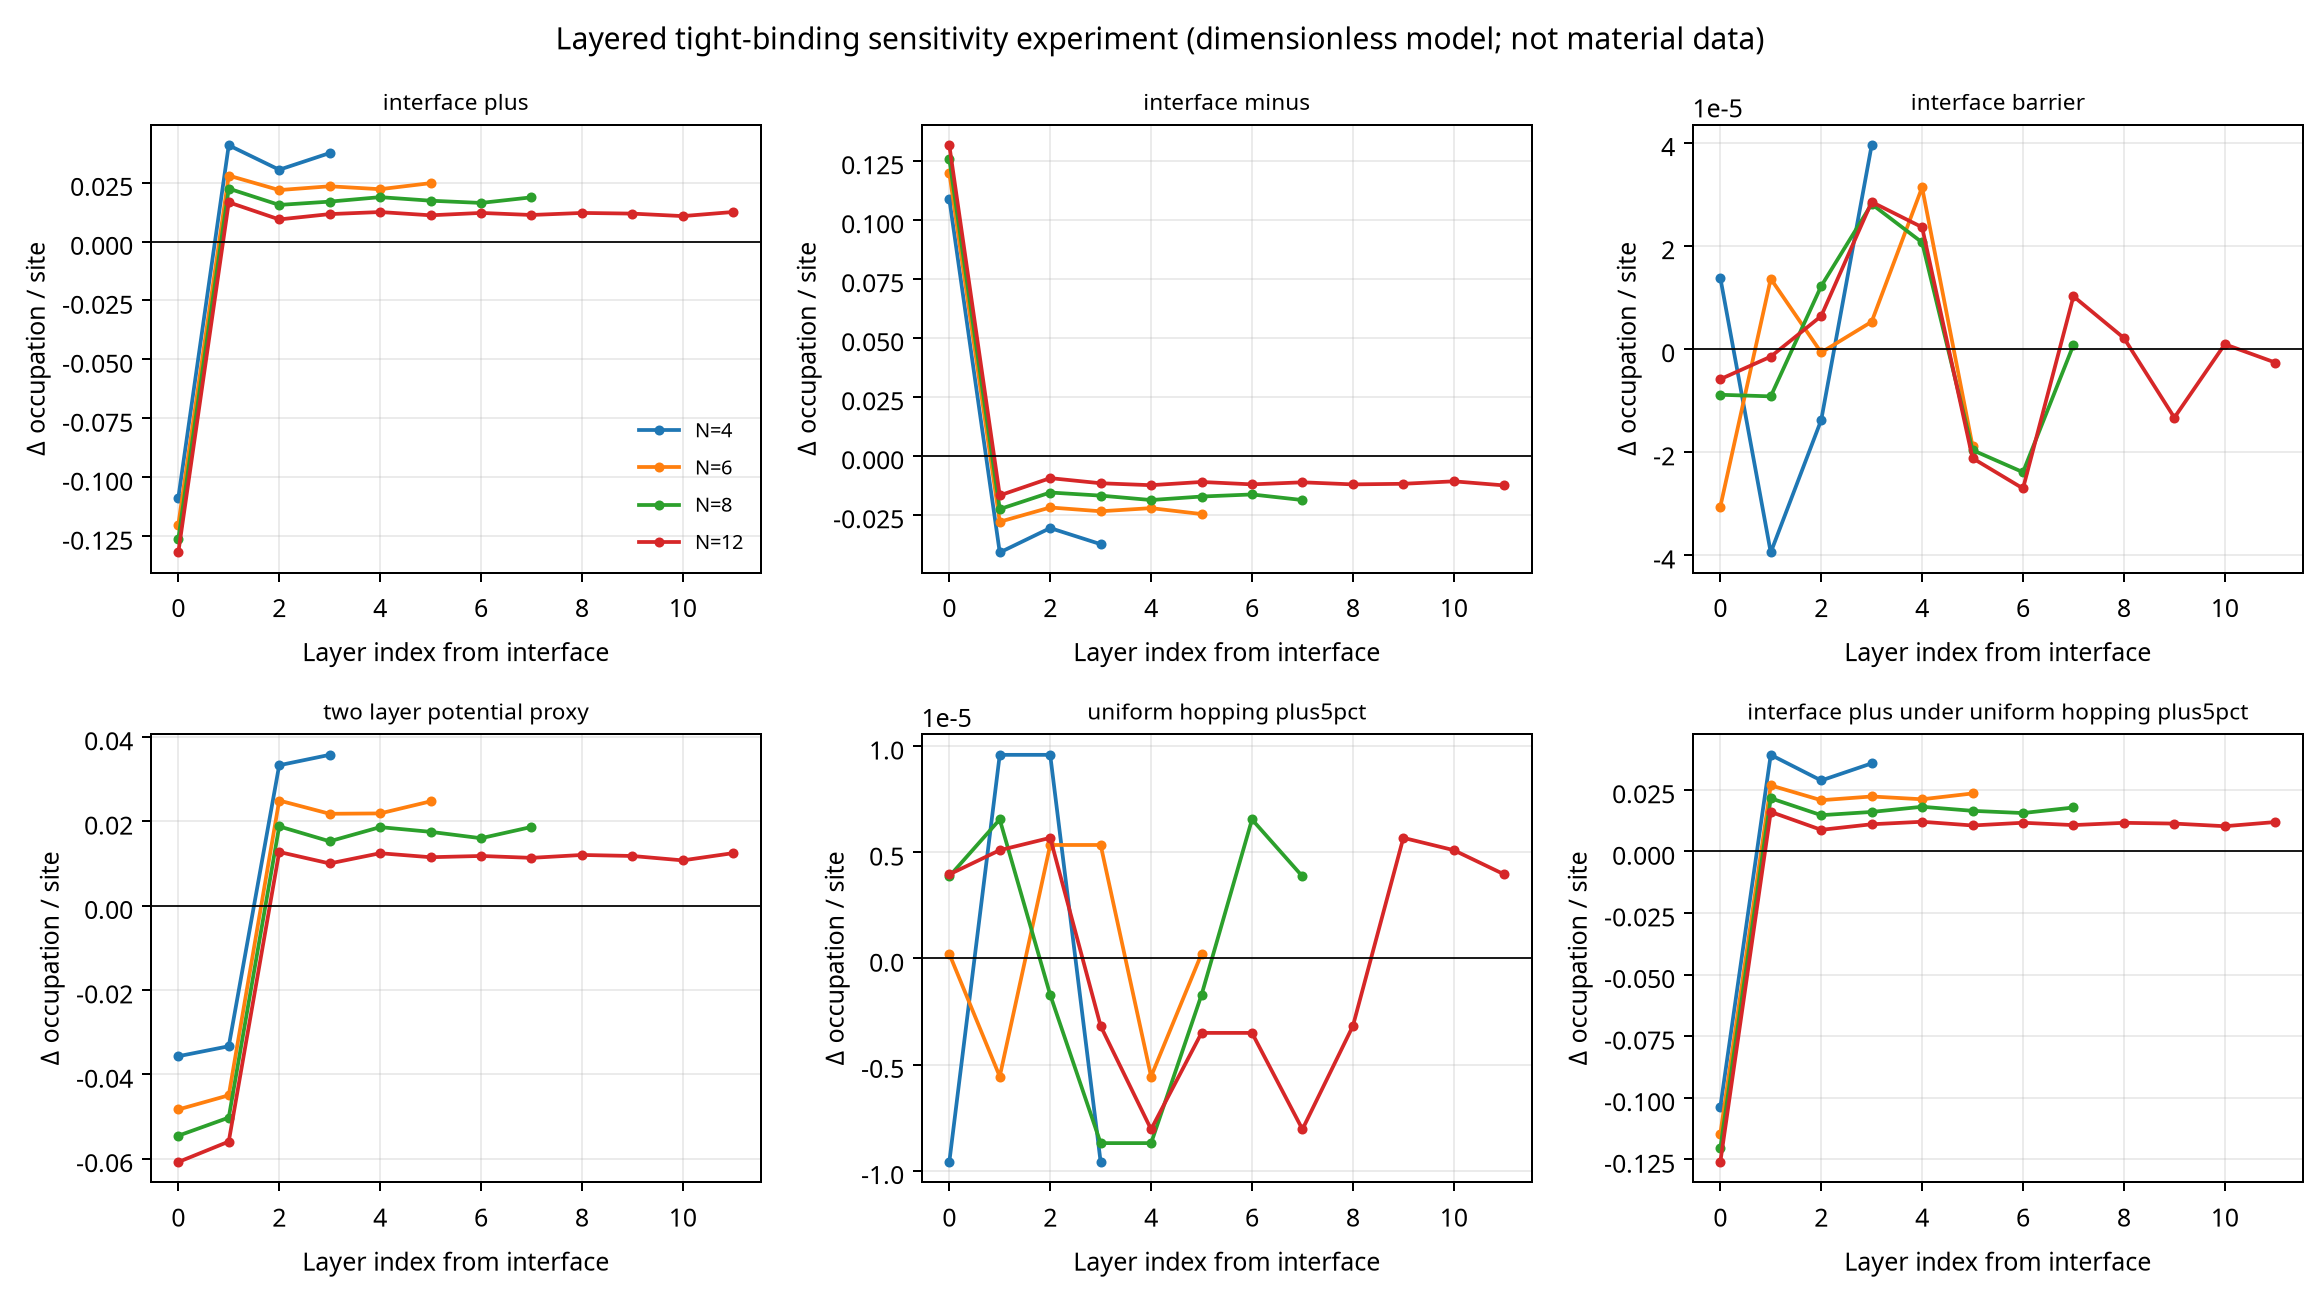

In [2]:
from IPython.display import Image, display
display(Image(filename='charge_reconstruction_profiles.png'))


## Output interpretation

The code writes four outputs into the working directory: `layer_charge_profiles.csv`, `model_summary.csv`, `k_grid_convergence.csv`, and `charge_reconstruction_profiles.png`. The exponential fit is a diagnostic only; low R² means that the predicted exponential decay is not supported by this model. The files are model-generated output, not experimental measurements.

To download files from Google Colab, run:
```python
from google.colab import files
for name in ['model_summary.csv', 'layer_charge_profiles.csv', 'k_grid_convergence.csv', 'charge_reconstruction_profiles.png']:
    files.download('/content/' + name)
```
